[Status] 0. Rendering Data & Valley Maps...
[Status] 1. Generating Dynamic Strokes & Color Blend...
[Status] 2. Slicing & Applying Greedy Optimization...
[Status] 3. Exporting Mockups & Rendering Global Preview...


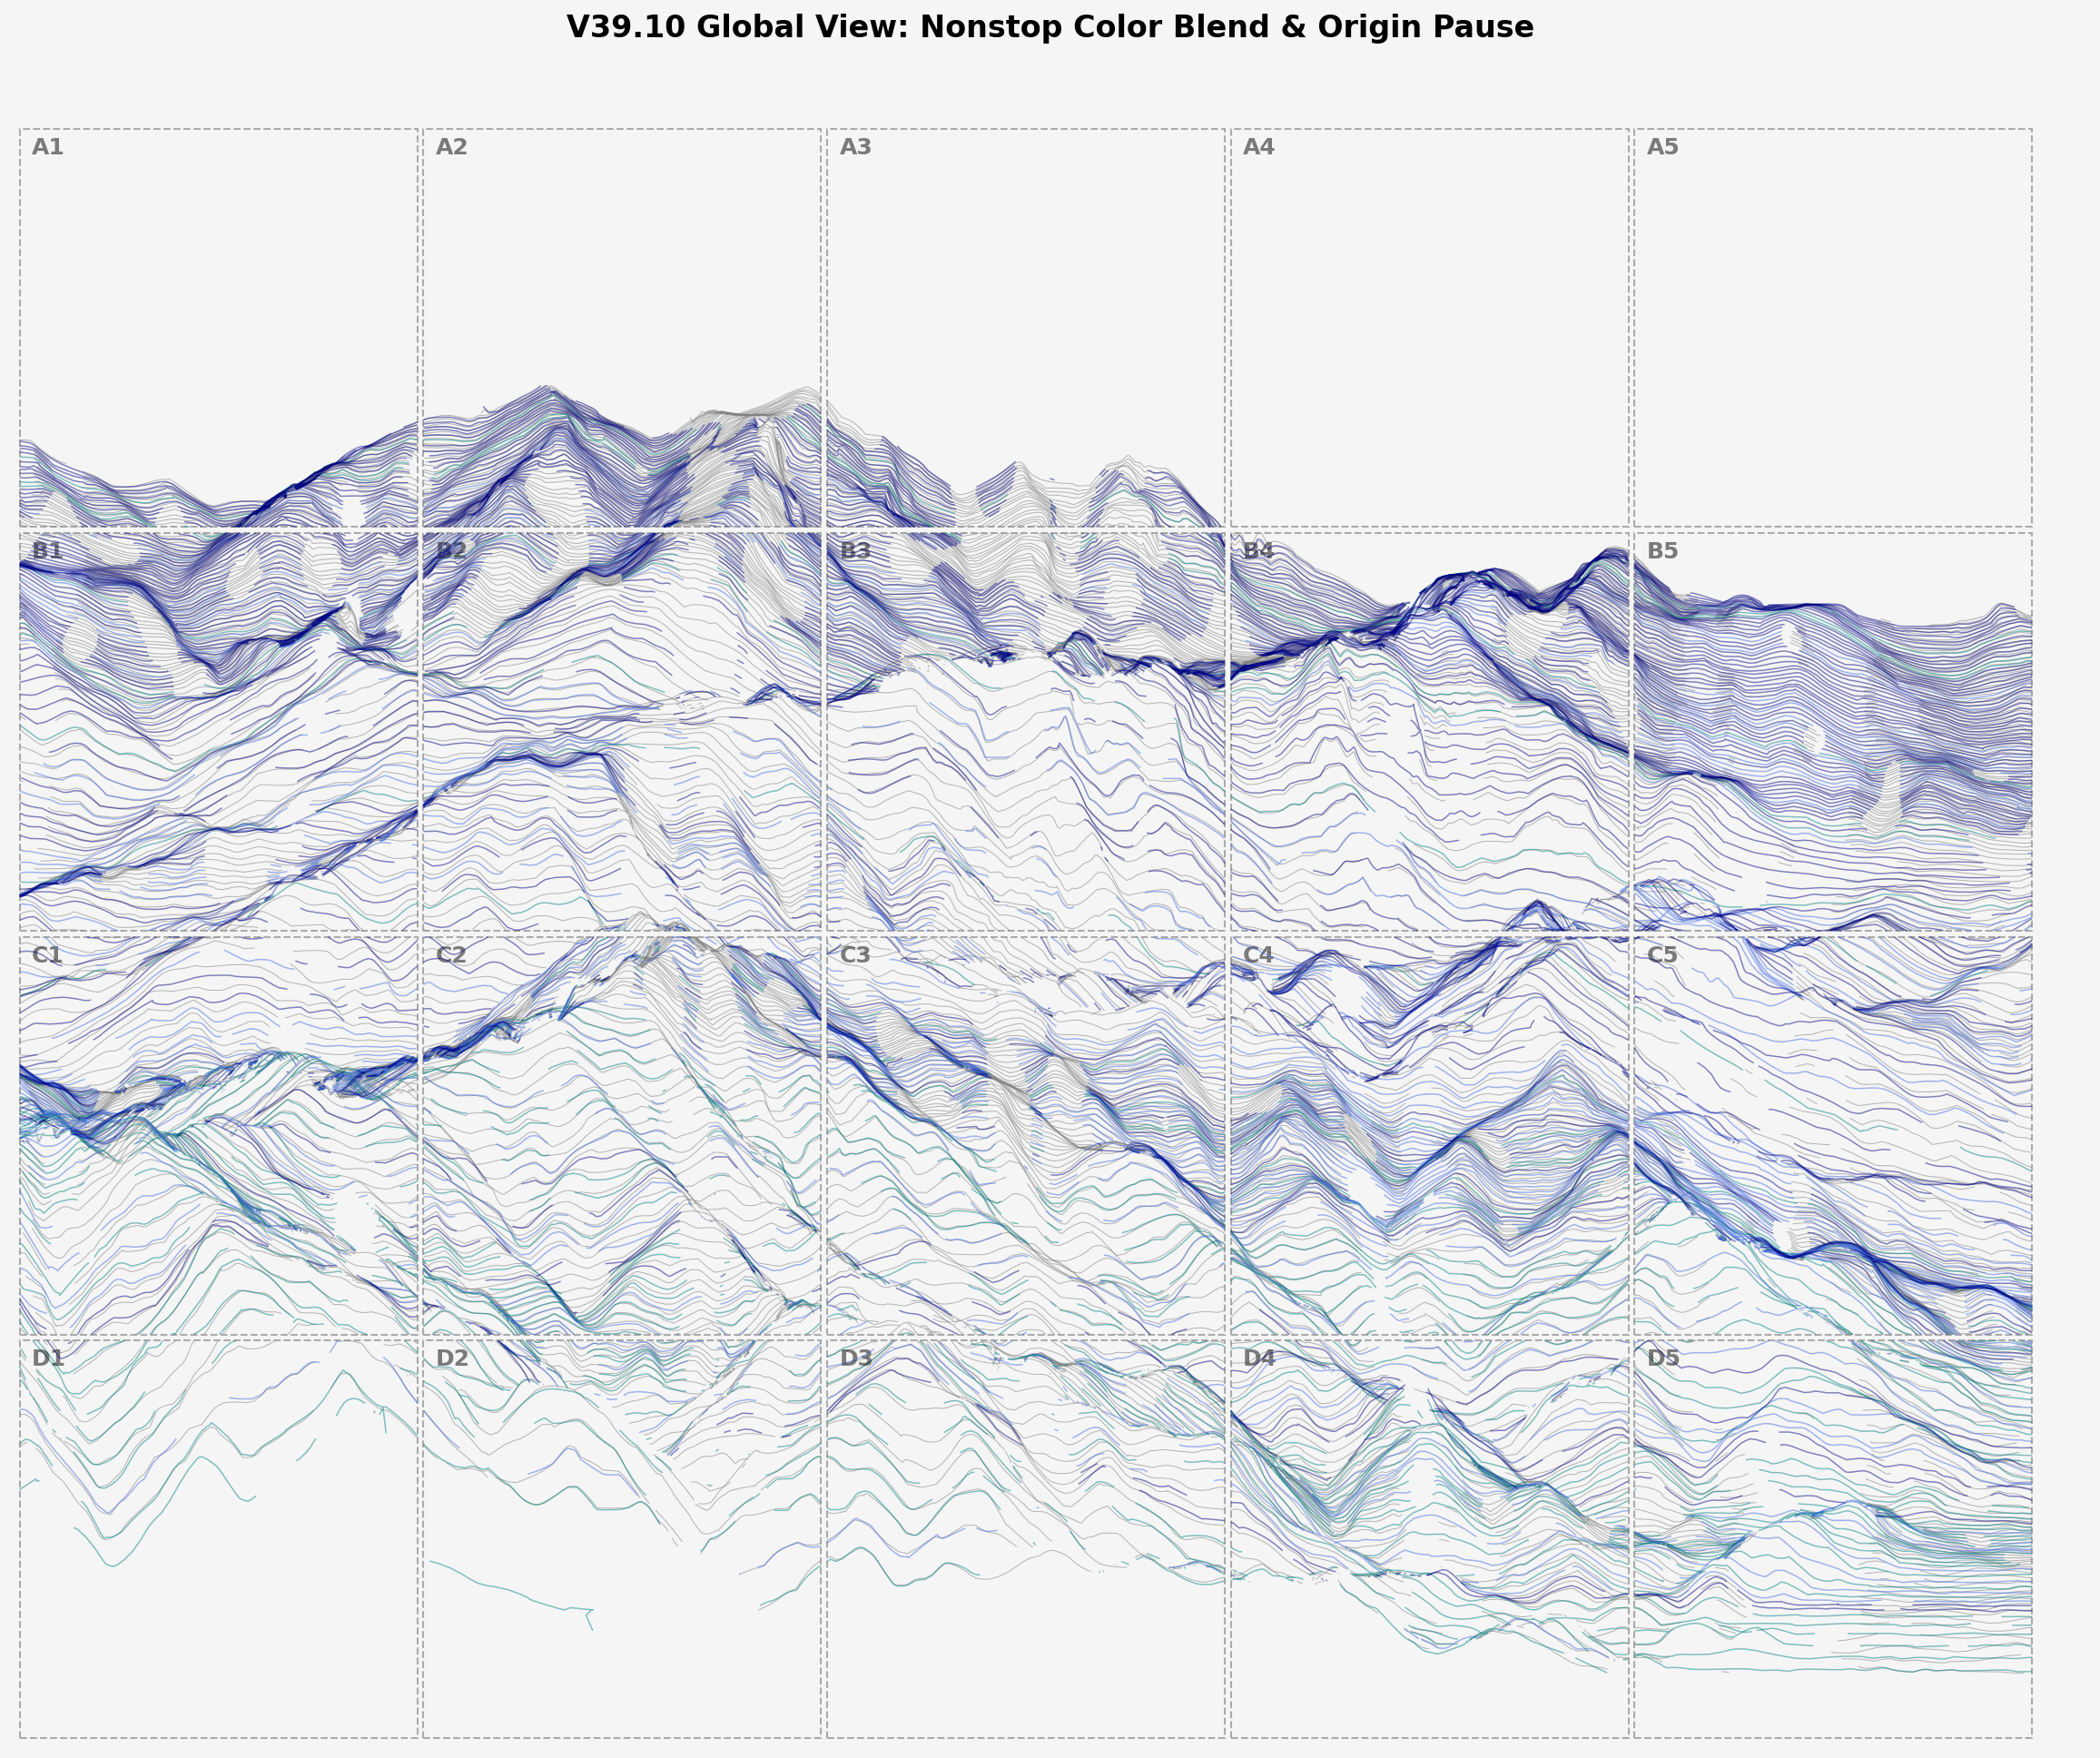

[Success] Done! All 20 G-codes and Mockups saved in: gcode_5x4_V39_10_Nonstop_Color


In [ ]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from shapely.geometry import LineString, box
from scipy.interpolate import CubicSpline
from scipy.interpolate import interp1d
import os
import cv2
import math
import random
import time

start_time = time.time()

# ==============================================================================
# [A-1] Core Engine Parameters (V39.10: 논스톱 컬러 진행)
# ==============================================================================
GAP_MIN = 2.0              
GAP_MAX = 35.0             

FEED_RATE_DRAW = 5000      
FEED_RATE_TRAVEL = 10000
FEED_RATE_WIPE = 5000      
FEED_RATE_Z_FAST = 4000    

Z_HOVER = 0.0              
Z_SAFE = 0.0               
Z_DIP = -11.0              

Z_TOUCH = -3.5             
Z_LIGHT_MIN = -4.0         
Z_LIGHT_MAX = -8.0         
Z_COLOR_DRAW = -4.5        

STATION_X = -20.0
STATIONS = {
    'color1': 35.0,    # 청록 (Teal)
    'color2': 120.0,   # 울트라마린 (Ultramarine)
    'color3': 205.0,   # 남색 (Navy)
    'light': 290.0     # 연묵 (Gray)
} 
DIP_LIMITS = {'color1': 600.0, 'color2': 600.0, 'color3': 600.0, 'light': 1200.0}

# ==============================================================================
# [A-2] Canvas Configuration (5x4)
# ==============================================================================
PANEL_W, PANEL_H = 325.0, 325.0 
MIN_DRAW, MAX_DRAW = 5.0, 330.0 

MULTI_VIEW_CONFIG = {
    'A': {'base_z_scale': 250.0, 'y_pitch': 0.8},
    'B': {'base_z_scale': 320.0, 'y_pitch': 0.6},
    'C': {'base_z_scale': 380.0, 'y_pitch': 0.4},
    'D': {'base_z_scale': 450.0, 'y_pitch': 0.5},
}

COLS, ROWS = 5, 4
TOTAL_W = PANEL_W * COLS + 5.0 * (COLS - 1)
TOTAL_H = PANEL_H * ROWS + 5.0 * (ROWS - 1)

panels = []
row_names = ['D', 'C', 'B', 'A'] 
for r_idx in range(ROWS):
    for c_idx in range(COLS):
        panels.append((f"{row_names[r_idx]}{c_idx+1}", c_idx * (PANEL_W + 5.0), r_idx * (PANEL_H + 5.0)))

output_dir = "gcode_5x4_V39_10_Nonstop_Color"
if not os.path.exists(output_dir): os.makedirs(output_dir)

# ==============================================================================
# [B] Slicer Algorithms
# ==============================================================================
def rdp_simplify_3d(pts, epsilon):
    if len(pts) < 3: return pts
    pts_arr = np.array(pts)
    a, b = pts_arr[0], pts_arr[-1]
    ab = b - a
    if np.all(ab == 0): dists = np.linalg.norm(pts_arr - a, axis=1)
    else: dists = np.linalg.norm(np.cross(pts_arr - a, ab), axis=1) / np.linalg.norm(ab)
    index = np.argmax(dists)
    if dists[index] >= epsilon:
        res1 = rdp_simplify_3d(pts[:index+1], epsilon)
        res2 = rdp_simplify_3d(pts[index:], epsilon)
        return res1[:-1] + res2
    else: return [pts[0], pts[-1]]

def smooth_spline_3d(path, res_factor=2):
    if len(path) < 4: return path
    pts = np.array(path)
    dists = np.sqrt(np.sum(np.diff(pts[:, :2], axis=0)**2, axis=1))
    valid_idx = np.where(dists > 0.1)[0]
    pts = pts[np.append(valid_idx, len(pts)-1)]
    if len(pts) < 4: return path
    t = np.linspace(0, 1, len(pts))
    t_new = np.linspace(0, 1, len(pts) * res_factor)
    try:
        cs_x, cs_y, cs_z = CubicSpline(t, pts[:, 0]), CubicSpline(t, pts[:, 1]), CubicSpline(t, pts[:, 2])
        return np.vstack([cs_x(t_new), cs_y(t_new), cs_z(t_new)]).T.tolist()
    except: return path

def optimize_paths_greedy(paths):
    if not paths: return []
    unvisited = list(paths)
    current_pt = (0.0, 0.0) 
    optimized = []
    while unvisited:
        best_idx, best_dist, reverse_needed = -1, float('inf'), False
        for i, p in enumerate(unvisited):
            d_start = math.hypot(current_pt[0] - p[0][0], current_pt[1] - p[0][1])
            d_end = math.hypot(current_pt[0] - p[-1][0], current_pt[1] - p[-1][1])
            if d_start < best_dist: best_dist, best_idx, reverse_needed = d_start, i, False
            if d_end < best_dist: best_dist, best_idx, reverse_needed = d_end, i, True
        chosen_path = unvisited.pop(best_idx)
        if reverse_needed: chosen_path = chosen_path[::-1]
        optimized.append(chosen_path)
        current_pt = (chosen_path[-1][0], chosen_path[-1][1])
    return optimized

# ==============================================================================
# [C] G-code Generation
# ==============================================================================
def get_wipe_gcode(station_y, name):
    return [f"(--- DIPPING: {name} ---)", f"G0 Z{Z_SAFE:.3f}", f"G0 X{STATION_X:.3f} Y{station_y:.3f} F{FEED_RATE_TRAVEL}", f"G1 Z{Z_DIP:.3f} F3000", f"G4 P1.5", f"G1 Y{station_y+2.0:.3f} F1000", f"G1 Y{station_y-2.0:.3f} F1000", f"G1 Y{station_y:.3f} F1000", f"G1 Z0.000 F{FEED_RATE_Z_FAST}", f"G1 X{STATION_X-4.0:.3f} F{FEED_RATE_WIPE}", f"G1 X{STATION_X+4.0:.3f} F{FEED_RATE_WIPE}", f"G1 X{STATION_X:.3f} F{FEED_RATE_WIPE}", f"G0 Z{Z_HOVER:.3f}"]

def get_manual_wash_pause_gcode():
    # 🌟 연묵이 끝난 후 원점(0,0,0)으로 이동해서 대기
    return [f"", f"(--- MANUAL BRUSH WASH REQUIRED! ---)", f"G0 Z0.000", f"G0 X0.000 Y0.000 F{FEED_RATE_TRAVEL}", f"M0 (Wash brush -> Press RESUME)", f"G4 P1.0", f""]

def generate_dynamic_paths(paths, ink_name):
    if not paths: return []
    station_y, gcode, drawn_len = STATIONS[ink_name], get_wipe_gcode(STATIONS[ink_name], ink_name), 0.0
    for pts in paths:
        sx, sy = np.clip(pts[0][0], MIN_DRAW, MAX_DRAW), np.clip(pts[0][1], MIN_DRAW, MAX_DRAW)
        gcode.extend([f"G0 Z{Z_HOVER:.3f}", f"G0 X{sx:.3f} Y{sy:.3f} F{FEED_RATE_TRAVEL}", f"G1 Z{pts[0][2]:.3f} F{FEED_RATE_Z_FAST}"]) 
        for i in range(1, len(pts)):
            px, py, pz = np.clip(pts[i][0], MIN_DRAW, MAX_DRAW), np.clip(pts[i][1], MIN_DRAW, MAX_DRAW), pts[i][2]
            gcode.append(f"G1 X{px:.3f} Y{py:.3f} Z{pz:.3f} F{FEED_RATE_DRAW if pz <= Z_TOUCH else FEED_RATE_TRAVEL}")
            if pz <= Z_TOUCH: drawn_len += math.hypot(px - np.clip(pts[i-1][0], MIN_DRAW, MAX_DRAW), py - np.clip(pts[i-1][1], MIN_DRAW, MAX_DRAW))
        if drawn_len > DIP_LIMITS[ink_name]:
            gcode.extend([f"G0 Z{Z_HOVER:.3f}"] + get_wipe_gcode(station_y, "Refill"))
            drawn_len = 0.0
    return gcode

# ==============================================================================
# [D] Data & Visibility Masking
# ==============================================================================
print("[Status] 0. Rendering Data & Valley Maps...")
data_dir = r"F:\GIT\Datascape\Kumgang\Manmulsang"
try:
    with rasterio.open(os.path.join(data_dir, 'Manmulsang_DEM.tif')) as src: raw_dem = src.read(1)
    dem_norm = np.clip(cv2.resize(raw_dem, (2000, 1600)) / np.max(raw_dem), 0, 1)
except:
    xx, yy = np.meshgrid(np.linspace(0, 5, 2000), np.linspace(0, 5, 1600))
    dem_norm = (np.sin(xx) * np.cos(yy) + 1) / 2

H, W = dem_norm.shape
noise_map = cv2.resize(np.random.rand(50, 60), (W, H), interpolation=cv2.INTER_CUBIC)
dy_map, dx_map = np.gradient(dem_norm)
slope = np.clip(np.sqrt(dx_map**2 + dy_map**2) / 0.2, 0, 1)

local_mean = cv2.GaussianBlur(dem_norm, (151, 151), 0)
valley_map = np.clip(local_mean - dem_norm, 0, 1)
valley_map = valley_map / (np.max(valley_map) + 1e-5) 

y_r_vec = np.linspace(0, 1.0, H)
x_r_vec = np.linspace(0, 1.0, W)

density_wave = interp1d([0.0, 0.25, 0.5, 0.75, 1.0], [1.0, 0.4, 0.2, 1.0, 0.6], kind='cubic')(x_r_vec)
interp_z = interp1d([1.0, 0.66, 0.33, 0.0], [MULTI_VIEW_CONFIG[k]['base_z_scale'] for k in ['A','B','C','D']], kind='cubic')
y_pitches = interp1d([1.0, 0.66, 0.33, 0.0], [MULTI_VIEW_CONFIG[k]['y_pitch'] for k in ['A','B','C','D']], kind='cubic')(y_r_vec)

Y_PHYS = (np.cumsum(y_pitches) / np.sum(y_pitches)) * (TOTAL_H - 150.0 - 250.0 - 50.0) + 50.0
Y_PHYS_MAX, Y_PHYS_MIN = np.max(Y_PHYS), np.min(Y_PHYS)

visibility_mask = np.zeros((H, W), dtype=bool); horizon = np.full(W, -np.inf)
for y in range(H):
    if y == int(H * 0.4) or y == int(H * 0.75): horizon = horizon - 250.0
    py_row = Y_PHYS[y] + (dem_norm[y, :] * interp_z(y/(H-1))) - 30.0
    visible = py_row >= horizon - 0.5
    visibility_mask[y, :] = visible
    horizon = np.where(visible, py_row, horizon)

def apply_accordion_x(x_idx, y_r, w_max):
    base_x = -100.0 + (x_idx / (w_max - 1)) * (TOTAL_W + 200.0)
    shift = math.sin(y_r * math.pi * 2.5) * 30.0 
    return base_x + shift

# ==============================================================================
# [E] Layer Generation (연산 병목 완벽 해결)
# ==============================================================================
print("[Status] 1. Generating Dynamic Strokes & Color Blend...")
paths_light_detail, paths_color1, paths_color2, paths_color3 = [], [], [], []

def get_dynamic_z(dem_val, slope_val, noise_val, valley_val, y_ratio, x_idx, is_color=False):
    density = density_wave[x_idx]
    pressure_factor = (1.0 - density) * 0.5 + slope_val * 0.5
    
    base_z = Z_LIGHT_MIN + pressure_factor * (Z_LIGHT_MAX - Z_LIGHT_MIN)
    if is_color: base_z = Z_COLOR_DRAW + (pressure_factor - 0.5) * 2.0 
    
    wave_slow = math.sin(x_idx * 0.02) * 1.0    
    wave_fast = math.cos(x_idx * 0.1) * 0.5     
    noise_bump = (noise_val - 0.5) * 1.5        
    
    fluctuation = wave_slow + wave_fast + noise_bump
    current_z = base_z + fluctuation
    
    if dem_val < 0.05 and y_ratio < 0.05: return Z_HOVER
    peak_protect = np.clip((dem_val - 0.4) / 0.3, 0.0, 1.0)
    mist_intensity = valley_val * (1.0 - slope_val) * (noise_val + 0.5)
    
    if mist_intensity > 0.35 and peak_protect == 0.0:
        fade = np.clip((mist_intensity - 0.35) / 0.4, 0.0, 1.0)
        current_z = current_z + (Z_HOVER - current_z) * fade
        
    return np.clip(current_z, Z_LIGHT_MAX, Z_HOVER)

curr_y = 0.0
while curr_y < H:
    y = int(curr_y); y_r = y / (H-1)
    avg_density = np.mean(density_wave)
    base_gap = GAP_MAX - (GAP_MAX - GAP_MIN) * (np.clip((np.max(dem_norm[y,:]) - 0.1) / 0.8, 0, 1) ** 2.0)
    gap = base_gap * (1.5 - avg_density * 0.5) 
    
    z_s, p_l = interp_z(y_r), []
    for x in range(W):
        rugged_y = (dem_norm[y,x] + (noise_map[y,x] - 0.5) * 0.02) * z_s
        px = apply_accordion_x(x, y_r, W)
        py = Y_PHYS[y] + rugged_y - 30.0
        
        if visibility_mask[y,x]: 
            dyn_z = get_dynamic_z(dem_norm[y,x], slope[y,x], noise_map[y,x], valley_map[y,x], y_r, x, False)
            p_l.append((px, py, dyn_z))
        else: p_l.append((px, py, Z_HOVER))
    
    paths_light_detail.append(p_l)
    curr_y += max(1.0, gap)

curr_y = 5.0
while curr_y < H:
    y = int(curr_y); y_r = y / (H-1)
    avg_density_row = np.mean(density_wave)
    fluid_multiplier = 1.5 - (avg_density_row * 0.5) 
    gap = GAP_MAX - (GAP_MAX - GAP_MIN * fluid_multiplier) * (np.clip((np.max(dem_norm[y,:]) - 0.1) / 0.8, 0, 1) ** 2.0)
    
    y_anchors = [0.0, 0.33, 0.66, 1.0]
    w1_vals = [0.80, 0.40, 0.10, 0.05]
    w2_vals = [0.15, 0.45, 0.45, 0.15]
    
    w1 = np.interp(y_r, y_anchors, w1_vals)
    w2 = np.interp(y_r, y_anchors, w2_vals)
    
    r = random.random()
    if r < w1: chosen_color = 1
    elif r < w1 + w2: chosen_color = 2
    else: chosen_color = 3
    
    z_s, c_p = interp_z(y_r), []
    for x in range(W):
        px = apply_accordion_x(x, y_r, W)
        py = Y_PHYS[y] + (dem_norm[y,x] * z_s) - 30.0
        fluid_noise_threshold = 0.35 - (density_wave[x] * 0.2) 
        
        if visibility_mask[y,x] and noise_map[y,x] > fluid_noise_threshold:
            dyn_z = get_dynamic_z(dem_norm[y,x], slope[y,x], noise_map[y,x], valley_map[y,x], y_r, x, True)
            c_p.append((px, py, dyn_z))
        else:
            c_p.append((px, py, Z_HOVER))
            
    if chosen_color == 1: paths_color1.append(c_p)
    elif chosen_color == 2: paths_color2.append(c_p)
    else: paths_color3.append(c_p)
    
    curr_y += max(1.5, gap * fluid_multiplier)

# ==============================================================================
# [F] Slicer Optimization
# ==============================================================================
print("[Status] 2. Slicing & Applying Greedy Optimization...")
strict_tile = box(MIN_DRAW, MIN_DRAW, MAX_DRAW, MAX_DRAW)
viz_data = []

def strict_slicer(g_list, x_off, y_off):
    res = []
    for item in g_list:
        smoothed_item = smooth_spline_3d(rdp_simplify_3d(item, epsilon=0.5), res_factor=2)
        local_p = [(pt[0] - x_off, pt[1] - y_off, pt[2]) for pt in smoothed_item]
        line = LineString([(pt[0], pt[1]) for pt in local_p])
        
        if line.intersects(strict_tile):
            inter = line.intersection(strict_tile)
            segs = [inter] if inter.geom_type == 'LineString' else [g for g in inter.geoms if g.geom_type == 'LineString']
            for s in segs:
                if len(s.coords) >= 2:
                    if LineString(s.coords).length < 3.0: continue
                    final_pts = [(cp[0], cp[1], local_p[np.argmin([math.hypot(cp[0]-lp[0], cp[1]-lp[1]) for lp in local_p])][2]) for cp in s.coords]
                    res.append(final_pts)
    return optimize_paths_greedy(res)

def apply_zigzag(paths):
    return [p[::-1] if i % 2 == 1 else p for i, p in enumerate(paths)]

for p_name, x_off, y_off in panels:
    pl_detail = strict_slicer(paths_light_detail, x_off, y_off)
    pc1 = strict_slicer(paths_color1, x_off, y_off)
    pc2 = strict_slicer(paths_color2, x_off, y_off)
    pc3 = strict_slicer(paths_color3, x_off, y_off)
    
    pl_detail = apply_zigzag(pl_detail)
    pc1 = apply_zigzag(pc1)
    pc2 = apply_zigzag(pc2)
    pc3 = apply_zigzag(pc3)
    
    master = ["G21", "G90", f"(--- {p_name} V39.10 NONSTOP COLOR ---)"]
    
    # 1. 흑백(연묵) 먼저 그리기
    master.extend(generate_dynamic_paths(pl_detail, 'light'))
    
    # 2. 🌟 연묵 끝난 후 원점 이동 및 사용자 세척 대기
    master.extend(get_manual_wash_pause_gcode())
    
    # 3. 🌟 멈춤 없이 컬러 1, 2, 3 논스톱 진행
    master.extend(generate_dynamic_paths(pc1, 'color1'))
    master.extend(generate_dynamic_paths(pc2, 'color2'))
    master.extend(generate_dynamic_paths(pc3, 'color3'))
    
    # 4. 모든 작업 완료 후 원점(0,0,0) 복귀
    master.extend(["G0 Z0.000", "G0 X0.000 Y0.000 F10000"])
    
    with open(os.path.join(output_dir, f"{p_name}_Master.gcode"), 'w', encoding='utf-8') as f: f.write("\n".join(master))
    viz_data.append({'name':p_name, 'x_off':x_off, 'y_off':y_off, 'light_detail':pl_detail, 'color1':pc1, 'color2':pc2, 'color3':pc3})

# ==============================================================================
# [G] Clean PNG Export & [H] Global Visualization
# ==============================================================================
print("[Status] 3. Exporting Mockups & Rendering Global Preview...")
mockup_dir = os.path.join(output_dir, "Mockups")
if not os.path.exists(mockup_dir): os.makedirs(mockup_dir)

cd = {
    'light_detail':('gray', 0.8, 0.7), 
    'color1':('#008080', 1.2, 0.6), 
    'color2':('#4169E1', 1.2, 0.6), 
    'color3':('#000080', 1.2, 0.6)  
}
zd = {'light_detail':1, 'color1':2, 'color2':3, 'color3':4}

def draw_layer(ax_t, data_dict, keys):
    for k in keys:
        segs = []
        for path in data_dict[k]:
            seg = []
            for pt in path:
                if pt[2] <= Z_TOUCH: seg.append((pt[0], pt[1])) 
                else:
                    if len(seg) > 1: segs.append(seg)
                    seg = []
            if len(seg) > 1: segs.append(seg)
        ax_t.add_collection(LineCollection(segs, colors=cd[k][0], lw=cd[k][1], alpha=cd[k][2], zorder=zd[k]))

for data in viz_data:
    fig_mock = plt.figure(figsize=(10, 10), dpi=300, facecolor='white')
    ax_mock = plt.Axes(fig_mock, [0., 0., 1., 1.]); ax_mock.set_axis_off(); fig_mock.add_axes(ax_mock)
    ax_mock.set_xlim(0, 335); ax_mock.set_ylim(0, 335); ax_mock.set_aspect('equal')
    draw_layer(ax_mock, data, ['light_detail', 'color1', 'color2', 'color3'])
    plt.savefig(os.path.join(mockup_dir, f"{data['name']}_Clean.png"), format='png', bbox_inches='tight', pad_inches=0)
    plt.close(fig_mock)

fig_global = plt.figure(figsize=(16, 13), dpi=150, facecolor='#f5f5f5')
ax_global = fig_global.add_subplot(111)
ax_global.set_title("V39.10 Global View: Nonstop Color Blend & Origin Pause", fontsize=16, fontweight='bold', pad=20)
ax_global.set_xlim(0, TOTAL_W + 50); ax_global.set_ylim(0, TOTAL_H + 50); ax_global.set_aspect('equal')
ax_global.axis('off')

for data in viz_data:
    x_o, y_o = data['x_off'], data['y_off']
    rect = plt.Rectangle((x_o + 5.0, y_o + 5.0), 325.0, 325.0, fill=False, color='black', lw=1, ls='--', alpha=0.3)
    ax_global.add_patch(rect)
    ax_global.text(x_o + 15, y_o + 310, data['name'], fontsize=12, fontweight='bold', alpha=0.5)
    
    for k in ['light_detail', 'color1', 'color2', 'color3']:
        segs = []
        for path in data[k]:
            seg = []
            for pt in path:
                if pt[2] <= Z_TOUCH: seg.append((pt[0] + x_o, pt[1] + y_o)) 
                else:
                    if len(seg) > 1: segs.append(seg)
                    seg = []
            if len(seg) > 1: segs.append(seg)
        ax_global.add_collection(LineCollection(segs, colors=cd[k][0], lw=cd[k][1]*0.6, alpha=cd[k][2]*0.8, zorder=zd[k]))

plt.tight_layout(); plt.show()
print(f"[Success] Done! All 20 G-codes and Mockups saved in: {output_dir}")